### Mode coupling at $2^{nd}$ order SPT density field

In [46]:
import sys; sys.path.insert(0, '../scripts')
import numpy as np, matplotlib.pyplot as plt
from exercise_2 import *
from exercise_3 import Pk_powerlaw, gaussian_field, kgrid, derivative_k, real_space_field, fourier_space_field

#### Gaussian field $\delta_1$
Drawn from a power-law spectrum $P_L(k)=A\,k^{n_s-3}$ with $A$ set so that the variance of $\delta_1$ on the grid is small,  ($\sigma_1 = 0.1$)

In [47]:
N, L = 256, 1000.0 
V = L**3
ns = 0.965
sigma_target = 0.1 # target std of delta_1 on the grid to deifne amplitude of seed P(k)

*_, k_mag = kgrid(N, L) 
nonzero = k_mag > 0
A = sigma_target**2 * V / (k_mag[nonzero]**(ns-3)).sum() # so sigma^2 = (1/V) sum_k P(k)
Pk = Pk_powerlaw(A, ns)

rng = np.random.default_rng(78)
delta1_k = gaussian_field(Pk, N, L, rng)
delta1_x = real_space_field(delta1_k, N, L)[0]
print(f"N = {N}, L = {L} Mpc/h, cell = {L/N:.2f} Mpc/h, A = {A:.3e} (Mpc/h)^(3+ns), seed = 78")
print(f"sigma_1 = {delta1_x.std():.4f} | mean delta_1 = {delta1_x.mean():.1e}")

N = 256, L = 1000.0 Mpc/h, cell = 3.91 Mpc/h, A = 1.949e-01 (Mpc/h)^(3+ns), seed = 78
sigma_1 = 0.0999 | mean delta_1 = 0.0e+00


#### Band limit and aliasing
A product of two fields with modes $|n_i|\le K$ has modes up to $2K$. On an $N^3$ mesh anything beyond $N/2$ wraps around to $n-N$ and lands on a retained mode if $K\ge N/3$.
To avoid aliasing, $\delta_2$ is built from a copy of $\delta_1$ truncated to $|n_i|<N/3$ ($k_{max}\lesssim\frac23 k_{Ny}$). 

In [48]:
mask = band_limit_mask(N)
n_max = (N - 1) // 3  # largest kept |n_i|
k_f, k_Ny = 2*np.pi/L, np.pi*N/L
print(f"kept modes: |n_i| <= {n_max} -> k_max = {n_max*k_f:.4f} h/Mpc = {n_max*k_f/k_Ny:.3f} k_Ny (k_Ny = {k_Ny:.4f} h/Mpc, k_f = {k_f:.4f} h/Mpc)")
print(f"fraction of modes kept = {mask.mean():.3f}")

delta1_trunc_x = real_space_field(delta1_k * mask, N, L)[0]
print(f"sigma_1 full = {delta1_x.std():.4f} | sigma_1 band-limited = {delta1_trunc_x.std():.4f}")

kept modes: |n_i| <= 85 -> k_max = 0.5341 h/Mpc = 0.664 k_Ny (k_Ny = 0.8042 h/Mpc, k_f = 0.0063 h/Mpc)
fraction of modes kept = 0.298
sigma_1 full = 0.0999 | sigma_1 band-limited = 0.0820


#### $\delta_{2,\mathbf{k}}=\frac{1}{V}\sum_{\mathbf{q}}F_2(\mathbf{q},\mathbf{k}-\mathbf{q})\,\delta_{1,\mathbf{q}}\,\delta_{1,\mathbf{k}-\mathbf{q}}$
With the symmetric EdS kernel
$F_2(\mathbf{k}_1,\mathbf{k}_2)=\frac57+\frac{\mu}{2}\left(\frac{k_1}{k_2}+\frac{k_2}{k_1}\right)+\frac27\mu^2$, $\mu=\hat{\mathbf{k}}_1\cdot\hat{\mathbf{k}}_2$.

The convolution is evaluated by transforming each term of $F_2$ in its corresponding real-space operator on $\delta_1$ and transforming the result back to Fourier space to avoid the sum in q:

$\delta_2(\mathbf{x})=\frac57\,\delta_1^2+\partial_i\delta_1\,\partial_i\phi+\frac27\,(\partial_i\partial_j\phi)(\partial_i\partial_j\phi)$, 

where $\partial_i\to ik_i$, $\nabla^{-2}\to-1/k^2$ and $\nabla^2\phi=\delta_1$

In [49]:
delta2_k, zero_mode = delta_2(delta1_k, N, L)
print(f"raw k = 0 mode / max|delta_2,k| = {abs(zero_mode) / np.abs(delta2_k).max():.1e}")

delta2_x, max_imag = real_space_field(delta2_k, N, L)
print(f"sigma_2 = {delta2_x.std():.4f} | sigma_2/sigma_1 = {delta2_x.std()/delta1_trunc_x.std():.3f} | max|Im delta_2(x)| / max|delta_2(x)| = {max_imag/np.abs(delta2_x).max():.1e}")

raw k = 0 mode / max|delta_2,k| = 1.4e-15
sigma_2 = 0.0281 | sigma_2/sigma_1 = 0.342 | max|Im delta_2(x)| / max|delta_2(x)| = 1.9e-16


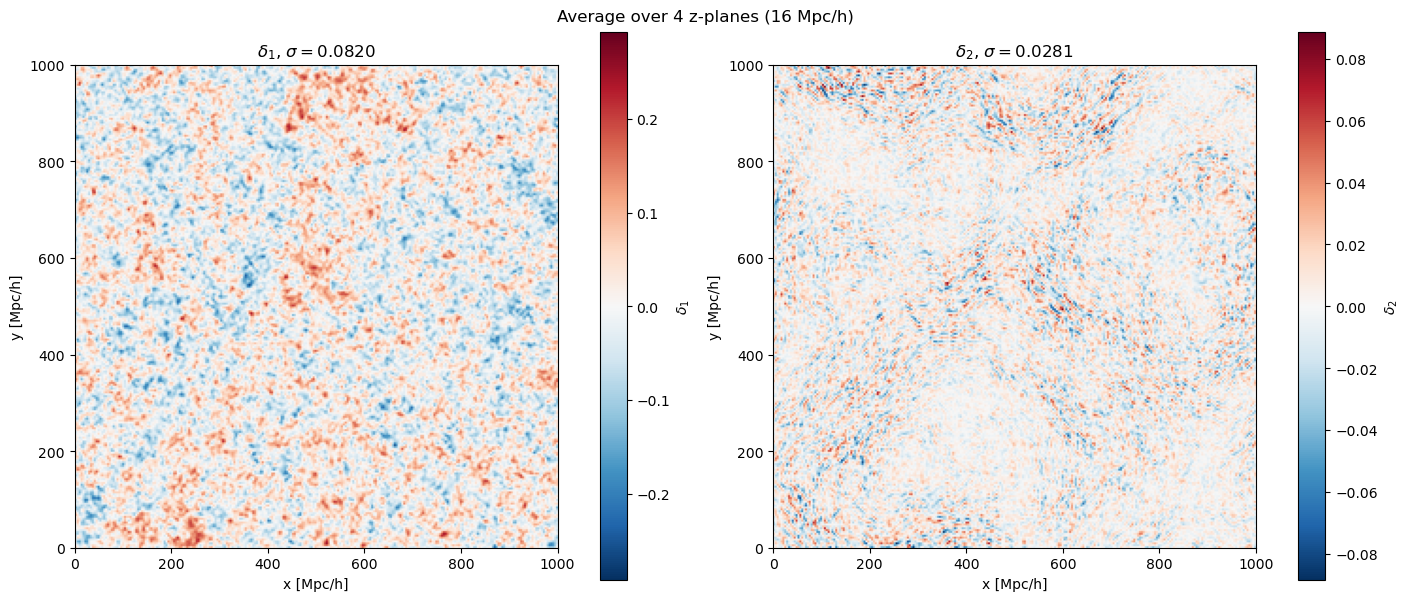

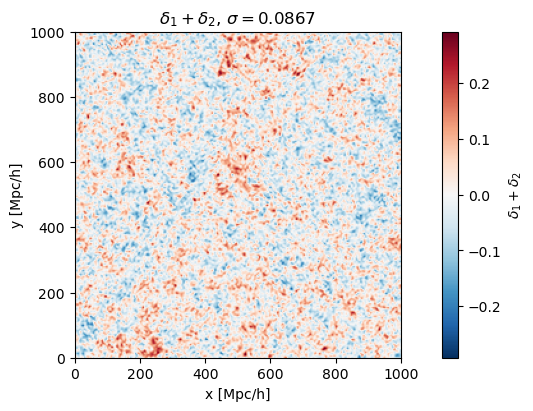

In [50]:
# average of delta_1, delta_2 and delta_1 + delta_2 over z-planes between 500 Mpc/h and 516 Mpc/h
# delta_1 and delta_1 + delta_2 share color scale and delta_2 has its own
iz, thickness = N // 2, 4
planes = iz + np.arange(thickness)
d1, d2, d12 = delta1_trunc_x, delta2_x, delta1_trunc_x + delta2_x
slab = lambda f: f[:, :, planes].mean(axis=2)
vmax_12 = max(np.abs(slab(d1)).max(), np.abs(slab(d12)).max())   # common scale for delta_1 and delta_1 + delta_2

def show(ax, f, vmax, t):
    im = ax.imshow(slab(f).T, origin='lower', extent=[0, L, 0, L], cmap='RdBu_r', vmin=-vmax, vmax=vmax)  # .T: imshow puts axis 0 vertical
    plt.colorbar(im, ax=ax, label=t)
    ax.set_title(f'{t}, $\\sigma = {f.std():.4f}$')
    ax.set_xlabel('x [Mpc/h]'); ax.set_ylabel('y [Mpc/h]')

fig, axs = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
show(axs[0], d1, vmax_12, r'$\delta_1$')
show(axs[1], d2, np.abs(slab(d2)).max(), r'$\delta_2$')
fig.suptitle(rf'Average over {thickness} z-planes ({thickness*L/N:.0f} Mpc/h)')
plt.show()

fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
show(ax, d12, vmax_12, r'$\delta_1+\delta_2$')
plt.show()



#### $\hat{P}(k) = \frac{1}{(N_k V)} \sum |\delta_k|^2$

42 shells up to k_max = 0.5341 h/Mpc | modes per shell: 92 to 177130


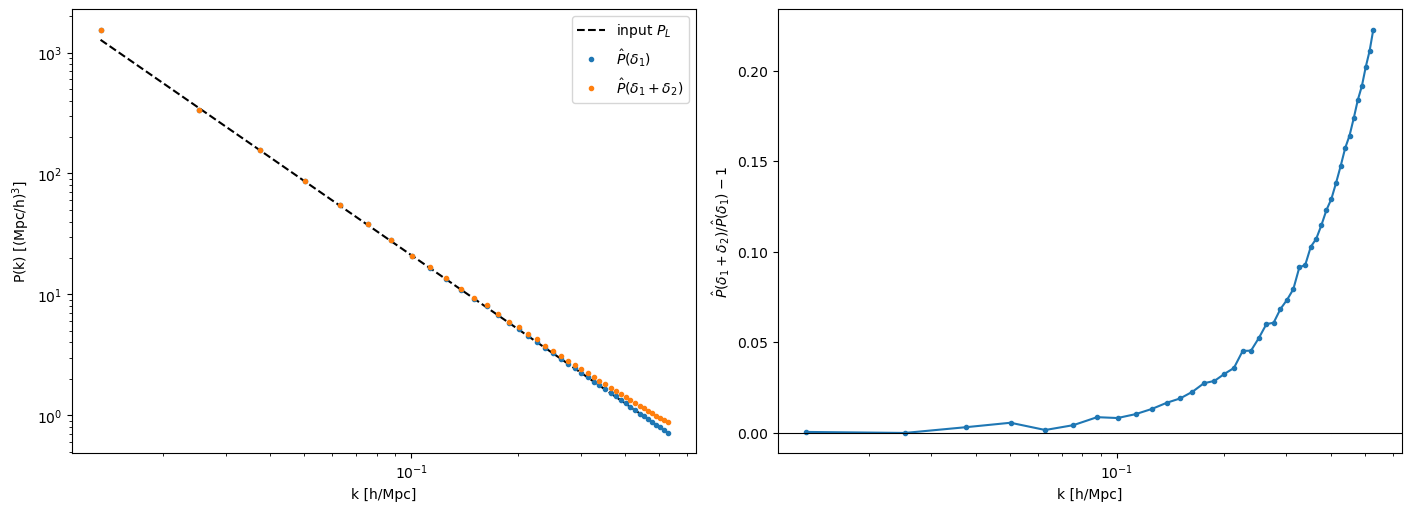

In [51]:
#P(k)
delta12_k = delta1_k + delta2_k  
nbins = (n_max - 1) // 2  # linear k shells of width ~ 2 k_f from k_f to k_max
k, P1, nk = power_spectrum(delta1_k, N, L, nbins) # linear density field
_, P12, _ = power_spectrum(delta12_k, N, L, nbins) # linear + second-order density field
print(f"{nbins} shells up to k_max = {n_max*k_f:.4f} h/Mpc | modes per shell: {nk.min():.0f} to {nk.max():.0f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
axs[0].loglog(k, Pk(k), 'k--', label=r'input $P_L$')
axs[0].loglog(k, P1, 'o', ms=3, label=r'$\hat{P}(\delta_1)$')
axs[0].loglog(k, P12, 'o', ms=3, label=r'$\hat{P}(\delta_1+\delta_2)$')
axs[0].set_xlabel('k [h/Mpc]'); axs[0].set_ylabel(r'P(k) [(Mpc/h)$^3$]'); axs[0].legend()
axs[1].semilogx(k, P12 / P1 - 1, 'o-', ms=3)
axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_xlabel('k [h/Mpc]'); axs[1].set_ylabel(r'$\hat{P}(\delta_1+\delta_2)/\hat{P}(\delta_1) - 1$')
plt.show()

#### $\hat{B_T}(k) = \frac{1}{N_TV}\sum_{T}\mathrm{Re}[\delta_{\mathbf{k}_1}\delta_{\mathbf{k}_2}\delta_{\mathbf{k}_3}] = \frac{\langle \delta_{s_1}(\mathbf{x})\,\delta_{s_2}(\mathbf{x})\,\delta_{s_3}(\mathbf{x})\rangle_{\mathbf{x}}}{V\,\langle I_{s_1}(\mathbf{x})\,I_{s_2}(\mathbf{x})\,I_{s_3}(\mathbf{x})\rangle_{\mathbf{x}}}$

##### Triangle bins
The triangle bins $T$ are combinations of 3 k shells $S_i=\{\mathbf{k}:\,k_{c,i}-\Delta k/2\le|\mathbf{k}|<k_{c,i}+\Delta k/2\}$, one for each side of the triangle. To avoid a loop over all closed triangles to compute the direct estimator $\hat B_T=\frac{1}{N_TV}\sum_{T}\mathrm{Re}[\delta_{\mathbf{k}_1}\delta_{\mathbf{k}_2}\delta_{\mathbf{k}_3}]$ we observe that 

\begin{equation}
\delta_{s_1}(\mathbf{x})\,\delta_{s_2}(\mathbf{x})\,\delta_{s_3}(\mathbf{x})\ = \frac{1}{V³}\sum\limits_{\mathbf{k_1}∈S_1, \mathbf{k_2}∈S_2, \mathbf{k_3}∈S_3} δ_{\mathbf{k_1}}δ_{\mathbf{k_2}}δ_{\mathbf{k3}} e^{i(\mathbf{k_1}+\mathbf{k_2}+\mathbf{k_3})·\mathbf{x}} \nonumber
\end{equation}

and therefore the average of the product over the grid cells is

\begin{equation}
\langle\delta_{s_1}(\mathbf{x})\,\delta_{s_2}(\mathbf{x})\,\delta_{s_3}(\mathbf{x})\rangle_{\mathbf{x}} = \frac{1}{V³}\sum\limits_{\mathbf{k_1}∈S_1, \mathbf{k_2}∈S_2, \mathbf{k_3}∈S_3} δ_{\mathbf{k_1}}δ_{\mathbf{k_2}}δ_{\mathbf{k3}} \delta^D(\mathbf{k_1}+\mathbf{k_2}+\mathbf{k_3}) \nonumber
\end{equation}

which selects only products corresponding to triangles ($\mathbf{k_1}+\mathbf{k_2}+\mathbf{k_3}=0$). From that,$\sum_{T}\delta_{\mathbf{k}_1}\delta_{\mathbf{k}_2}\delta_{\mathbf{k}_3}$ can be written as $V^3 \langle\delta_{s_1}(\mathbf{x})\,\delta_{s_2}(\mathbf{x})\,\delta_{s_3}(\mathbf{x})\rangle_{\mathbf{x}}$ and $\hat B_T$ can be estimated as

\begin{equation}
\hat B_T=\frac{\langle\delta_{s_1}\delta_{s_2}\delta_{s_3}\rangle_{\mathbf{x}}}{V\langle I_{s_1}I_{s_2}I_{s_3}\rangle_{\mathbf{x}}} \ ,\ \ \ \ \ \ N_T=V^3\langle I_{s_1}I_{s_2}I_{s_3}\rangle_{\mathbf{x}} \nonumber
\end{equation}

The following operations are performed:

- $\delta_{\mathbf{k}}$ is filtered to each shell and transformed to real space ( $\delta_{s}(\mathbf{x})=\frac1V\sum_{\mathbf{k}\in S}\delta_{\mathbf{k}}e^{i\mathbf{k}\cdot\mathbf{x}}$). The shell mask is also transformed to obtain $I_s(\mathbf{x})$.
- The cell average of the product of the three filtered fields $\langle\delta_{s_1}\delta_{s_2}\delta_{s_3}\rangle_{\mathbf{x}}=\frac{1}{V^3}\sum_T\delta_{\mathbf{k}_1}\delta_{\mathbf{k}_2}\delta_{\mathbf{k}_3}$ is taken. 
- The same product for the mask fields is tanken to count the triangles: $\langle I_{s_1}I_{s_2}I_{s_3}\rangle_{\mathbf{x}}=N_T/V^3$

$\hat B_T$ is measured for $\delta_1$ and for $\delta_1+\delta_2$ on the same realization. Since a Gaussian field does not have a connected bispectrum, $\hat B_T(\delta_1)$ should be consistent with zero up to sampling noise. Because the noise is common to both fields, it cancels when taking $\hat B_T(\delta_1+\delta_2)-\hat B_T(\delta_1)$.

In [52]:
# B_T for delta_1, delta_2 and delta_1 + delta_2 in equilateral bins at different scales
kcs = np.array([6, 10, 16, 24, 40, 64]) # shell centres in units of k_f
dk = 2 * k_f # shell width in units of k_f
fields = {'d1': delta1_k, 'd2': delta2_k, 'd12': delta12_k}
B = {name: [] for name in fields}
for k_c in kcs:
    m = shell_mask(k_mag, k_c * k_f, dk)
    for name, f in fields.items():
        B[name].append(bispectrum(f, [m, m, m], N, L)[0])
B = {name: np.array(v) for name, v in B.items()}

In [53]:
k_eq = kcs * k_f # h/Mpc
print(k_eq)

[0.03769911 0.06283185 0.10053096 0.15079645 0.25132741 0.40212386]


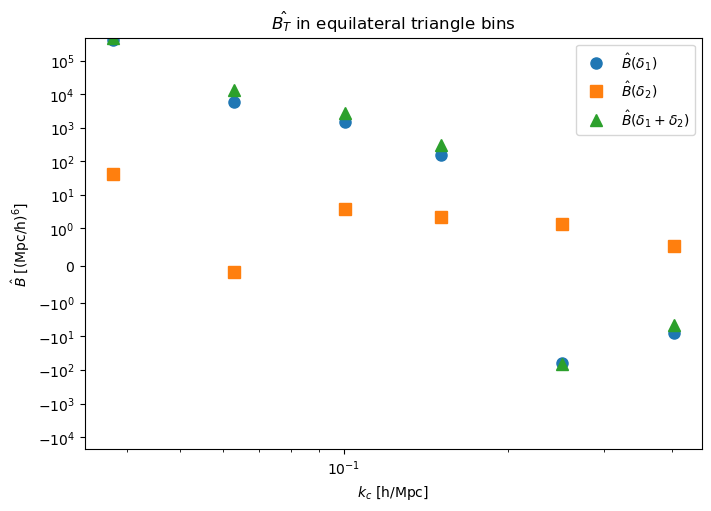

In [54]:
fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
for name, label, marker in (('d1', r'$\hat{B}(\delta_1)$', 'o'), ('d2', r'$\hat{B}(\delta_2)$', 's'),
                            ('d12', r'$\hat{B}(\delta_1+\delta_2)$', '^')):
    ax.plot(k_eq, B[name], marker, ms=8, label=label)
ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=1)   # values change sign and span many decades
ax.set_xlabel(r'$k_c$ [h/Mpc]'); ax.set_ylabel(r'$\hat{B}$ [(Mpc/h)$^6$]'); ax.legend()
ax.set_title(r'$\hat{B_T}$ in equilateral triangle bins')
plt.show()

In [68]:
# test of higher order statisatics over many realizations (now for N=64, same L, linear spectrum and sigma_1)
N_c = 64
*_, k_mag_c = kgrid(N_c, L)
A_c = sigma_target**2 * V / (k_mag_c[k_mag_c > 0]**(ns-3)).sum()   # amplitude that gives sigma_1 = 0.1 on this grid
Pk_c = Pk_powerlaw(A_c, ns)
n_max_c = (N_c - 1) // 3
print(f"N_c = {N_c}: k_max = {n_max_c} k_f = {n_max_c*k_f:.4f} h/Mpc, A = {A_c:.3e} (Mpc/h)^(3+ns)")

dk = 2 * k_f
bins_c = {'equil. with sides in bin centered at 6 k_f': (6, 6, 6), 'equil. with sides in bin centered at 10 k_f': (10, 10, 10), 'equil. with sides in bin centered at 14 k_f': (14, 14, 14),
          'isosc. with sides in bin centered at (14,14,6) k_f': (14, 14, 6)}
masks_c = {name: [shell_mask(k_mag_c, k_c * k_f, dk) for k_c in centres] for name, centres in bins_c.items()}


N_c = 64: k_max = 21 k_f = 0.1319 h/Mpc, A = 7.545e-01 (Mpc/h)^(3+ns)


In [69]:
# B_tree averaged over the closed triangles of each bin
B_tree, n_tri = {}, {}
for (name, centres), masks in zip(bins_c.items(), masks_c.values()):
    B_tree[name], n_tri[name] = tree_bispectrum(masks, N_c, L, Pk_c)
    point = f", 12/7 P_L^2(k_c) = {12/7 * Pk_c(centres[0]*k_f)**2:.3e}" if len(set(centres)) == 1 else ""
    print(f"{name}: <B_tree> = {B_tree[name]:.3e} (Mpc/h)^6 over {n_tri[name]} triangles{point}")


equil. with sides in bin centered at 6 k_f: <B_tree> = 7.144e+05 (Mpc/h)^6 over 129864 triangles, 12/7 P_L^2(k_c) = 6.078e+05
equil. with sides in bin centered at 10 k_f: <B_tree> = 8.031e+04 (Mpc/h)^6 over 648120 triangles, 12/7 P_L^2(k_c) = 7.601e+04
equil. with sides in bin centered at 14 k_f: <B_tree> = 1.989e+04 (Mpc/h)^6 over 1720368 triangles, 12/7 P_L^2(k_c) = 1.932e+04
isosc. with sides in bin centered at (14,14,6) k_f: <B_tree> = 1.221e+05 (Mpc/h)^6 over 727008 triangles


In [57]:
# bispectrum of delta_1 and delta_1 + delta_2 over N_r realizations
n_real = 400
B1, B12 = np.zeros((n_real, len(bins_c))), np.zeros((n_real, len(bins_c)))
for s in range(n_real):
    d1_k = gaussian_field(Pk_c, N_c, L, np.random.default_rng(1000 + s))
    d2_k, _ = delta_2(d1_k, N_c, L)
    for j, (name, masks) in enumerate(masks_c.items()):
        B1[s, j], N_T = bispectrum(d1_k, masks, N_c, L)
        B12[s, j], _ = bispectrum(d1_k + d2_k, masks, N_c, L)
        if s == 0:
            assert round(N_T) == n_tri[name], f"{name}: N_T from the estimator ({N_T:.0f}) differs from the triangle count of the prediction ({n_tri[name]})"
print(f"for {n_real} realizations, triangle counts of estimator and prediction agree in all bins")


for 400 realizations, triangle counts of estimator and prediction agree in all bins


In [58]:
# statistics: mean and standard error of the mean
mean = lambda x: x.mean(axis=0)
sem = lambda x: x.std(axis=0, ddof=1) / np.sqrt(len(x)) # standard error of the mean
diff = B12 - B1  # paired difference (Gaussian noise cancels in it)
B_pred = np.array([B_tree[name] for name in bins_c])

for j, name in enumerate(bins_c):
    print(f"{name}: N_T = {n_tri[name]} | <B_tree> = {B_pred[j]:.3e}")
    print(f"    B(d1)       = {mean(B1)[j]:+.3e} +- {sem(B1)[j]:.1e}  (mean/error = {mean(B1)[j]/sem(B1)[j]:+.1f})")
    print(f"    B(d1+d2)    = {mean(B12)[j]:+.3e} +- {sem(B12)[j]:.1e}  (mean/<B_tree> = {mean(B12)[j]/B_pred[j]:.2f}, (mean - <B_tree>)/error = {(mean(B12)[j]-B_pred[j])/sem(B12)[j]:+.1f})")
    print(f"    difference  = {mean(diff)[j]:+.3e} +- {sem(diff)[j]:.1e}  (mean/<B_tree> = {mean(diff)[j]/B_pred[j]:.2f}, (mean - <B_tree>)/error = {(mean(diff)[j]-B_pred[j])/sem(diff)[j]:+.1f})")


equil. with sides in bin centered at 6 k_f: N_T = 129864 | <B_tree> = 7.144e+05
    B(d1)       = +3.078e+04 +- 1.6e+05  (mean/error = +0.2)
    B(d1+d2)    = +7.166e+05 +- 1.6e+05  (mean/<B_tree> = 1.00, (mean - <B_tree>)/error = +0.0)
    difference  = +6.858e+05 +- 2.1e+04  (mean/<B_tree> = 0.96, (mean - <B_tree>)/error = -1.3)
equil. 10 with sides in bin centered at 6 k_f: N_T = 648120 | <B_tree> = 8.031e+04
    B(d1)       = +6.925e+03 +- 1.5e+04  (mean/error = +0.5)
    B(d1+d2)    = +8.517e+04 +- 1.5e+04  (mean/<B_tree> = 1.06, (mean - <B_tree>)/error = +0.3)
    difference  = +7.824e+04 +- 3.0e+03  (mean/<B_tree> = 0.97, (mean - <B_tree>)/error = -0.7)
equil. 14 with sides in bin centered at 6 k_f: N_T = 1720368 | <B_tree> = 1.989e+04
    B(d1)       = -1.268e+03 +- 3.3e+03  (mean/error = -0.4)
    B(d1+d2)    = +1.722e+04 +- 3.5e+03  (mean/<B_tree> = 0.87, (mean - <B_tree>)/error = -0.8)
    difference  = +1.848e+04 +- 8.2e+02  (mean/<B_tree> = 0.93, (mean - <B_tree>)/error = 

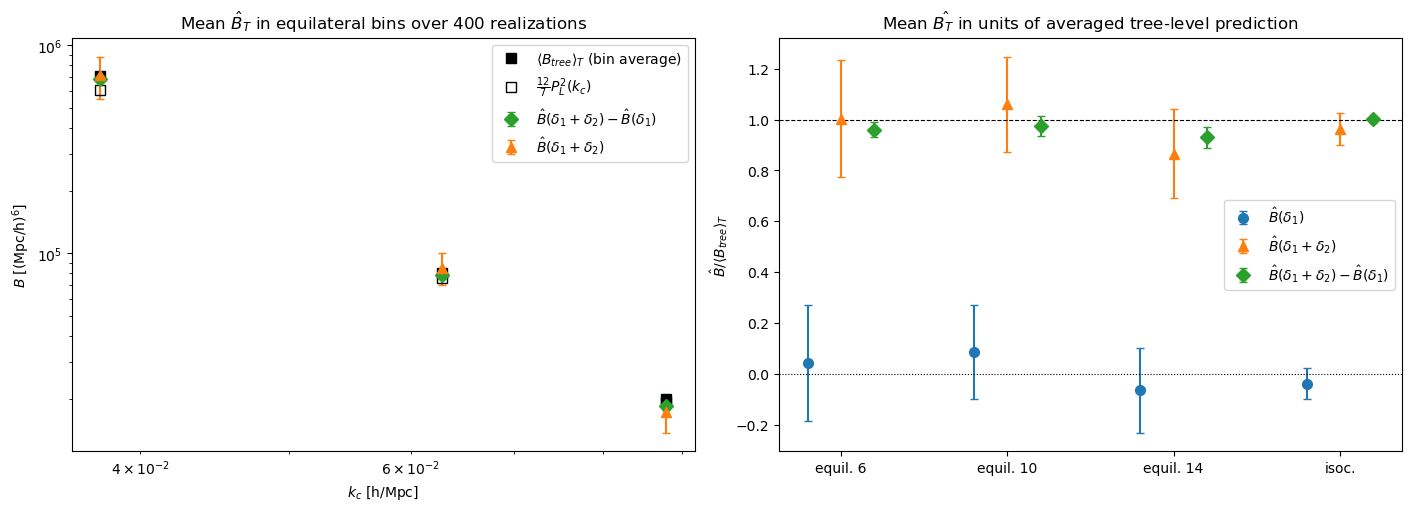

In [72]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

# left: equilateral bins, ensemble means with standard errors against the prediction
eq = [j for j, centres in enumerate(bins_c.values()) if len(set(centres)) == 1]
k_eq_c = np.array([list(bins_c.values())[j][0] for j in eq]) * k_f
axs[0].errorbar(k_eq_c, mean(diff)[eq], sem(diff)[eq], fmt='D', ms=7, capsize=3, color='C2', label=r'$\hat{B}(\delta_1+\delta_2)-\hat{B}(\delta_1)$')
axs[0].errorbar(k_eq_c, mean(B12)[eq], sem(B12)[eq], fmt='^', ms=7, capsize=3, color='C1', label=r'$\hat{B}(\delta_1+\delta_2)$')
axs[0].plot(k_eq_c, B_pred[eq], 'ks', ms=7, label=r'$\langle B_{tree}\rangle_T$ (bin average)')
axs[0].plot(k_eq_c, 12/7 * Pk_c(k_eq_c)**2, 's', mfc='none', mec='k', ms=7, label=r'$\frac{12}{7}P_L^2(k_c)$')
axs[0].set_xscale('log'); axs[0].set_yscale('log')
axs[0].set_xlabel(r'$k_c$ [h/Mpc]'); axs[0].set_ylabel(r'$B$ [(Mpc/h)$^6$]'); axs[0].legend(); axs[0].set_title(r'Mean $\hat{B}_T$ in equilateral bins over ' + f'{n_real} realizations')

# right: all bins, ensemble means in units of the bin-averaged prediction (expected: 0 for delta_1, 1 for delta_1 + delta_2 and for the difference)
x = np.arange(len(bins_c))
for dx, y, marker, label in ((-0.2, B1, 'o', r'$\hat{B}(\delta_1)$'), (0, B12, '^', r'$\hat{B}(\delta_1+\delta_2)$'),
                             (0.2, diff, 'D', r'$\hat{B}(\delta_1+\delta_2)-\hat{B}(\delta_1)$')):
    axs[1].errorbar(x + dx, mean(y) / B_pred, sem(y) / B_pred, fmt=marker, ms=7, capsize=3, label=label)
axs[1].axhline(1, color='k', ls='--', lw=0.8); axs[1].axhline(0, color='k', ls=':', lw=0.8)
axs[1].set_xticks(x, ['equil. 6', 'equil. 10', 'equil. 14', 'isoc.']); axs[1].set_ylabel(r'$\hat{B} / \langle B_{tree}\rangle_T$'); axs[1].legend()
axs[1].set_title(r'Mean $\hat{B_T}$' + f' in units of averaged tree-level prediction')
plt.show()


#### Resolution, box size, realization scatter and input amplitude tests

In [60]:
def bispectrum_ensemble(N, L, sigma, kcs, dk, n_real, seed0=1000):
    """For equilateral bins with shell centres kcs and width dk (both in h/Mpc), 
    returns B_tree (bin average), B(d1), B(d1+d2) per realization and bin of 
    n_real realizations with sigma_1 = sigma on an N^3 mesh"""
    V, k_f = L**3, 2*np.pi/L
    *_, k_mag = kgrid(N, L)
    Pk = Pk_powerlaw(sigma**2 * V / (k_mag[k_mag > 0]**(ns-3)).sum(), ns)
    k_max = ((N - 1) // 3) * k_f
    kcs = np.array([k_c for k_c in kcs if k_c + dk/2 <= k_max]) # selects well-resolved bins
    masks = [[shell_mask(k_mag, k_c, dk)] * 3 for k_c in kcs]
    B_tree = np.array([tree_bispectrum(m, N, L, Pk)[0] for m in masks])
    B1, B12 = np.zeros((n_real, len(kcs))), np.zeros((n_real, len(kcs)))
    for s in range(n_real):
        d1_k = gaussian_field(Pk, N, L, np.random.default_rng(seed0 + s))
        d2_k, _ = delta_2(d1_k, N, L)
        for j, m in enumerate(masks):
            B1[s, j] = bispectrum(d1_k, m, N, L)[0]
            B12[s, j] = bispectrum(d1_k + d2_k, m, N, L)[0]
    return {'k_c': kcs, 'B_tree': B_tree, 'B1': B1, 'B12': B12}

In [61]:
k_f0 = 2*np.pi / 1000.0  # k_f of L = 1000 Mpc/h box
dk_phys = 2 * k_f0 # shell width in h/Mpc
n_test = 30  # realizations per setting

##### Resolution


In [62]:
# For L=1000 Mpc/h and sigma_1=0.1 fixed, test of meshs with N=32, 48, 64, 96
# Ratio to the prediction is shown as a function of k_c/k_Ny

def ratio(res):
    """ mean paired difference in units of <B_tree> with standard error and scatter of B(d1) per realization in units of <B_tree>"""
    d = res['B12'] - res['B1']
    return d.mean(axis=0) / res['B_tree'], d.std(axis=0, ddof=1) / np.sqrt(len(d)) / res['B_tree'], res['B1'].std(axis=0, ddof=1) / res['B_tree']

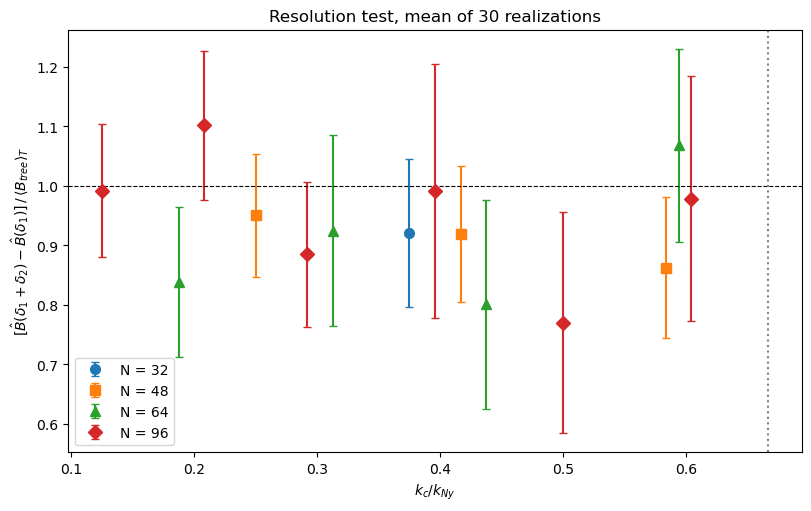

In [63]:
kcs_res = np.array([6, 10, 14, 19, 24, 29]) * k_f0  # shell centres in h/Mpc
res_N = {N_ : bispectrum_ensemble(N_, 1000.0, 0.1, kcs_res, dk_phys, n_test) for N_ in (32, 48, 64, 96)}

fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
for (N_, res), marker in zip(res_N.items(), 'os^D'):
    r, err, _ = ratio(res)
    ax.errorbar(res['k_c'] / (np.pi * N_ / 1000.0), r, err, fmt=marker, ms=7, capsize=3, label=f'N = {N_}')
ax.axhline(1, color='k', ls='--', lw=0.8); ax.axvline(2/3, color='gray', ls=':')
ax.set_xlabel(r'$k_c / k_{Ny}$'); ax.set_ylabel(r'$[\hat{B}(\delta_1+\delta_2)-\hat{B}(\delta_1)]\,/\,\langle B_{tree}\rangle_T$')
ax.set_title(f'Resolution test, mean of {n_test} realizations'); ax.legend()
plt.show()


##### Box size


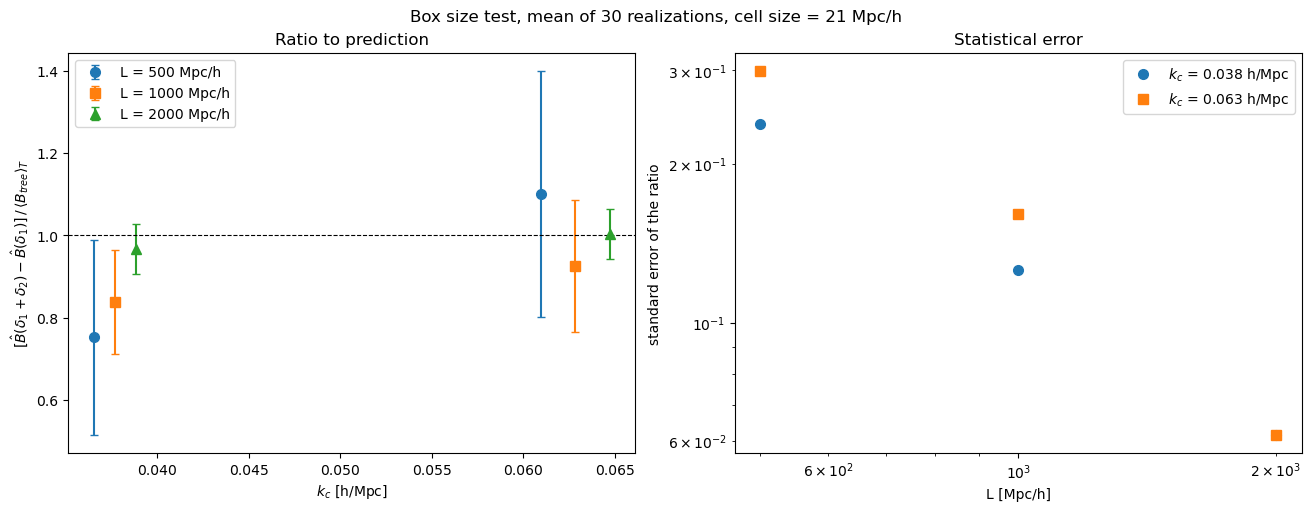

In [64]:
# cell size is kept fixed, L=500, 1000, 2000 Mpc/h with N=32, 64, 128, so k_Ny and k_max are the same 
# only the number of modes, and therefore of triangles per bin, changes
kcs_box = np.array([6, 10]) * k_f0 # shell centres in h/Mpc
res_L = {L_ : bispectrum_ensemble(N_, L_, 0.1, kcs_box, dk_phys, n_test) for L_, N_ in ((500.0, 32), (1000.0, 64), (2000.0, 128))}

fig, axs = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for i, (L_, res) in enumerate(res_L.items()):
    r, err, _ = ratio(res)
    axs[0].errorbar(res['k_c'] * (1 + 0.03 * (i - 1)), r, err, fmt='os^'[i], ms=7, capsize=3, label=f'L = {L_:.0f} Mpc/h')   # small shifts in k_c to separate the points
axs[0].axhline(1, color='k', ls='--', lw=0.8)
axs[0].set_xlabel(r'$k_c$ [h/Mpc]'); axs[0].set_ylabel(r'$[\hat{B}(\delta_1+\delta_2)-\hat{B}(\delta_1)]\,/\,\langle B_{tree}\rangle_T$')
axs[0].set_title('Ratio to prediction'); axs[0].legend()

errs = np.array([ratio(res)[1] for res in res_L.values()]) # standard errors, shape (number of boxes, number of bins)
for j, marker in enumerate('os'):
    axs[1].plot(list(res_L), errs[:, j], marker, ms=7, label=rf'$k_c$ = {kcs_box[j]:.3f} h/Mpc')
axs[1].set_xscale('log'); axs[1].set_yscale('log')
axs[1].set_xlabel('L [Mpc/h]'); axs[1].set_ylabel('standard error of the ratio'); axs[1].set_title('Statistical error'); axs[1].legend()
fig.suptitle(f'Box size test, mean of {n_test} realizations, cell size = {L_/N_:.0f} Mpc/h')
plt.show()


$\frac{\hat{B}(\delta_1+\delta_2)-\hat{B}(\delta_1)}{\langle B_{tree} \rangle_T}$ approaches 1 with smaller errors as box size grows especially for triangle bins centered at smaller k values, though all of them are consistent with 1. Smaller statistical errors are expected, since for larger boxes, more triangles fall into each bin.

##### Input amplitude


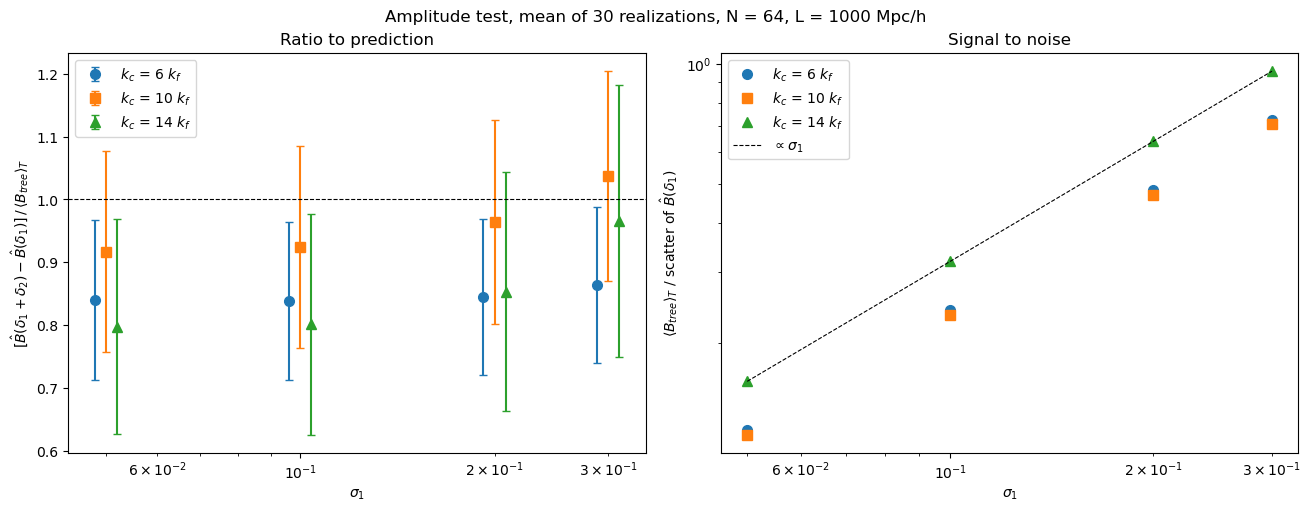

In [65]:
# N=64, L=1000 Mpc/h, sigma_1=0.05, 0.1, 0.2, 0.3
sigmas = np.array([0.05, 0.1, 0.2, 0.3])
kcs_amp = np.array([6, 10, 14]) * k_f0
res_s = {s_ : bispectrum_ensemble(64, 1000.0, s_, kcs_amp, dk_phys, n_test) for s_ in sigmas}

fig, axs = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for j, (k_c, marker) in enumerate(zip(kcs_amp, 'os^')):
    out = np.array([[ratio(res)[i][j] for i in range(3)] for res in res_s.values()])
    axs[0].errorbar(sigmas * (1 + 0.04 * (j - 1)), out[:, 0], out[:, 1], fmt=marker, ms=7, capsize=3, label=rf'$k_c$ = {k_c/k_f0:.0f} $k_f$')
    axs[1].plot(sigmas, 1 / out[:, 2], marker, ms=7, label=rf'$k_c$ = {k_c/k_f0:.0f} $k_f$') # signal to noise
axs[0].axhline(1, color='k', ls='--', lw=0.8); axs[0].set_xscale('log')
axs[0].set_xlabel(r'$\sigma_1$'); axs[0].set_ylabel(r'$[\hat{B}(\delta_1+\delta_2)-\hat{B}(\delta_1)]\,/\,\langle B_{tree}\rangle_T$'); axs[0].legend(); axs[0].set_title('Ratio to prediction')
axs[1].plot(sigmas, sigmas / sigmas[0] / out[0, 2], 'k--', lw=0.8, label=r'$\propto \sigma_1$')   # reference slope, through the first point of the last bin
axs[1].set_xscale('log'); axs[1].set_yscale('log')
axs[1].set_xlabel(r'$\sigma_1$'); axs[1].set_ylabel(r'$\langle B_{tree}\rangle_T$ / scatter of $\hat{B}(\delta_1)$'); axs[1].legend(); axs[1].set_title('Signal to noise')
fig.suptitle(f'Amplitude test, mean of {n_test} realizations, N = 64, L = 1000 Mpc/h')
plt.show()


$\frac{\hat{B}(\delta_1+\delta_2)-\hat{B}(\delta_1)}{\langle B_{tree} \rangle_T}$ approaches 1 as $\sigma_1$ grows for the triangle bins centered at 10 and 14 $k_f$. All of them are consistent with 1. For all bins, the signal to noise improves at higher amplitudes.


##### Non-gaussian signal and finite-sampling noise

In [66]:
# scatter of B(d1) over the realizations of the ensemble test against
# Gaussian noise estimate: sqrt(s V P1 P2 P3 / N_T), 
# where s is the symmetry factor of the triangle shape (6 for equilateral, 2 for isosceles, 1 for scalene)
for j, (name, centres) in enumerate(bins_c.items()):
    s_tri = {1: 6, 2: 2, 3: 1}[len(set(centres))]
    P = [Pk_c(k_c * k_f) for k_c in centres]
    sigma_B = np.sqrt(s_tri * V * P[0] * P[1] * P[2] / n_tri[name])
    print(f"{name}: scatter of B(d1) = {B1[:, j].std(ddof=1):.2e} | sqrt(s V P1 P2 P3 / N_T) = {sigma_B:.2e} | ratio = {B1[:, j].std(ddof=1)/sigma_B:.2f}")


equil. with sides in bin centered at 6 k_f: scatter of B(d1) = 3.27e+06 | sqrt(s V P1 P2 P3 / N_T) = 3.12e+06 | ratio = 1.05
equil. 10 with sides in bin centered at 6 k_f: scatter of B(d1) = 2.97e+05 | sqrt(s V P1 P2 P3 / N_T) = 2.94e+05 | ratio = 1.01
equil. 14 with sides in bin centered at 6 k_f: scatter of B(d1) = 6.63e+04 | sqrt(s V P1 P2 P3 / N_T) = 6.46e+04 | ratio = 1.03
isosc. with sides in bin centered at (14,14,6) k_f: scatter of B(d1) = 1.49e+05 | sqrt(s V P1 P2 P3 / N_T) = 1.36e+05 | ratio = 1.09


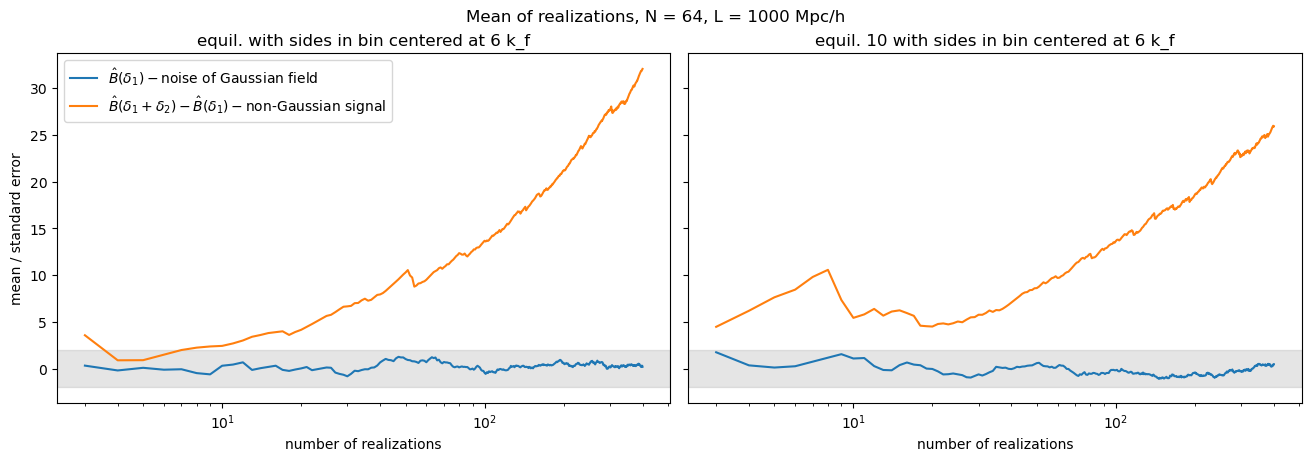

In [67]:
# ensemble mean in units of its standard error as n of realizations grow 
def running_z(x):
    k = np.arange(1, len(x) + 1)
    m = np.cumsum(x) / k
    var = (np.cumsum(x**2) - k * m**2)[2:] / (k[2:] - 1) # sample variance
    return k[2:], m[2:] / np.sqrt(var / k[2:])

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained', sharey=True)
for ax, j in zip(axs, (0, 1)):
    ax.plot(*running_z(B1[:, j]), label=r'$\hat{B}(\delta_1) - $noise of Gaussian field')
    ax.plot(*running_z(diff[:, j]), label=r'$\hat{B}(\delta_1+\delta_2)-\hat{B}(\delta_1) - $non-Gaussian signal')
    ax.axhspan(-2, 2, color='gray', alpha=0.2)
    ax.set_xscale('log'); ax.set_xlabel('number of realizations'); ax.set_title(list(bins_c)[j])
axs[0].set_ylabel('mean / standard error'); axs[0].legend()
fig.suptitle(f'Mean of realizations, N = 64, L = 1000 Mpc/h')
plt.show()


The ensemble mean of $\hat B(\delta_1)$ stays within $\pm 2$ standard errors as the number of realizations grows, which is expected for a Gaussian field with zero bispectrum. The mean of the difference $\hat B(\delta_1+\delta_2)-\hat B(\delta_1)$, however is non-zero and grows at about $\sqrt{N_r}$.